# 01 — EDA dos Espectogramas STFT

**Dataset:** Siena Scalp EEG (PhysioNet) | **Projeto:** epilepsy-detection

Análise exploratória dos espectogramas gerados pelo notebook `00_data_conversion.ipynb`. O objetivo é verificar a integridade, distribuição e características das imagens antes de avançar para a etapa de treinamento.

Para restringir a análise a um subconjunto de pacientes, configure `PATIENTS_TO_ANALYZE` na célula de setup.

---
**Seções:**
```
0. Setup
1. Inventário
2. Formato e Dimensões
3. Intensidade por Classe
4. Artefatos Visuais
5. Duplicatas e Imagens Similares
6. Desbalanceamento
7. Relatório
8. Export
```


## 0. Setup


In [1]:
import sys, os, hashlib, warnings
from pathlib import Path
from datetime import datetime
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from scipy import stats as scipy_stats
from PIL import Image, ImageFile, UnidentifiedImageError
ImageFile.LOAD_TRUNCATED_IMAGES = True
from tqdm import tqdm

PROJECT_ROOT = Path(globals()['_dh'][0]).parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SPECTROGRAMS_DIR = PROJECT_ROOT / 'data' / 'processed' / 'spectrograms'
ANNOT_PATH       = PROJECT_ROOT / 'data' / 'annotations' / 'annotations.csv'
DOCS_DIR         = PROJECT_ROOT / 'docs'
EDA_REPORT_PATH  = DOCS_DIR / 'eda_report.md'
FIGURES_DIR      = DOCS_DIR / 'eda_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Configuração principal
# None = todos os pacientes com espectogramas disponíveis
# Exemplo: ['PN00', 'PN01']
PATIENTS_TO_ANALYZE = None

CLASSES        = ['pre_ictal', 'ictal', 'pos_ictal', 'normal']
CLASSES_LABELS = {'pre_ictal': 'Pre-Ictal', 'ictal': 'Ictal',
                  'pos_ictal': 'Pos-Ictal', 'normal': 'Normal'}
CLASS_COLORS   = {'pre_ictal': '#3498db', 'ictal': '#e74c3c',
                  'pos_ictal': '#2ecc71',  'normal': '#95a5a6'}

# Threshold do dHash: número de bits distintos para classificar um par como 'similar'
# Espectogramas STFT de EEG tendem a ter regiões escuras dominantes;
# um threshold muito alto gera falsos positivos. Valor conservador: 2.
DHASH_THRESHOLD = 2

print(f'Projeto          : {PROJECT_ROOT}')
print(f'Espectogramas    : {SPECTROGRAMS_DIR}')
print(f'Figuras          : {FIGURES_DIR}')
print(f'Pacientes filter : {PATIENTS_TO_ANALYZE if PATIENTS_TO_ANALYZE else "todos"}')


Projeto          : /home/orlandomota/Documents/repositorios_github/epilepsy-detection
Espectogramas    : /home/orlandomota/Documents/repositorios_github/epilepsy-detection/data/processed/spectrograms
Figuras          : /home/orlandomota/Documents/repositorios_github/epilepsy-detection/docs/eda_figures
Pacientes filter : todos


## 1. Inventário


In [2]:
def _parse_class(stem: str) -> str:
    # Verifica do nome mais longo para o mais curto para evitar match parcial
    # (pre_ictal e pos_ictal ambos terminam em ictal)
    for cls in ['pre_ictal', 'pos_ictal', 'normal', 'ictal']:
        if stem.endswith('_' + cls):
            return cls
    return 'unknown'

def discover_images(base_dir: Path, patients_filter=None) -> pd.DataFrame:
    records = []
    if not base_dir.exists():
        print(f'Diretorio nao encontrado: {base_dir}')
        print('Execute 00_data_conversion.ipynb primeiro.')
        return pd.DataFrame()
    for patient_dir in sorted(d for d in base_dir.iterdir() if d.is_dir()):
        pid = patient_dir.name
        if patients_filter and pid not in patients_filter:
            continue
        for img_path in sorted(patient_dir.glob('*.png')):
            stem    = img_path.stem
            cls     = _parse_class(stem)
            sz_part = [p for p in stem.split('_') if p.startswith('seizure')]
            sz_n    = int(sz_part[0].replace('seizure', '')) if sz_part else -1
            edf     = stem.split('_seizure')[0] + '.edf' if '_seizure' in stem else 'unknown'
            records.append({
                'patient_id'  : pid,
                'edf_file'    : edf,
                'seizure_n'   : sz_n,
                'class'       : cls,
                'filename'    : img_path.name,
                'path'        : str(img_path),
                'file_size_kb': round(img_path.stat().st_size / 1024, 2),
            })
    return pd.DataFrame(records) if records else pd.DataFrame()

df = discover_images(SPECTROGRAMS_DIR, PATIENTS_TO_ANALYZE)

if df.empty:
    print('Nenhum espectograma encontrado.')
else:
    print(f'Total de imagens : {len(df)}')
    print(f'Pacientes        : {sorted(df.patient_id.unique())}')
    print(f'Por classe       : {df["class"].value_counts().reindex(CLASSES, fill_value=0).to_dict()}')
    display(df.head())


Total de imagens : 20
Pacientes        : ['PN00']
Por classe       : {'pre_ictal': 5, 'ictal': 5, 'pos_ictal': 5, 'normal': 5}


,patient_id,edf_file,seizure_n,class,filename,path,file_size_kb
0,PN00,PN00-1.edf,1,ictal,PN00-1_seizure01_ictal.png,/home/orlandomota/Documents/repositorios_githu...,16.71
1,PN00,PN00-1.edf,1,normal,PN00-1_seizure01_normal.png,/home/orlandomota/Documents/repositorios_githu...,9.57
2,PN00,PN00-1.edf,1,pos_ictal,PN00-1_seizure01_pos_ictal.png,/home/orlandomota/Documents/repositorios_githu...,22.93
3,PN00,PN00-1.edf,1,pre_ictal,PN00-1_seizure01_pre_ictal.png,/home/orlandomota/Documents/repositorios_githu...,9.48
4,PN00,PN00-2.edf,2,ictal,PN00-2_seizure02_ictal.png,/home/orlandomota/Documents/repositorios_githu...,17.00


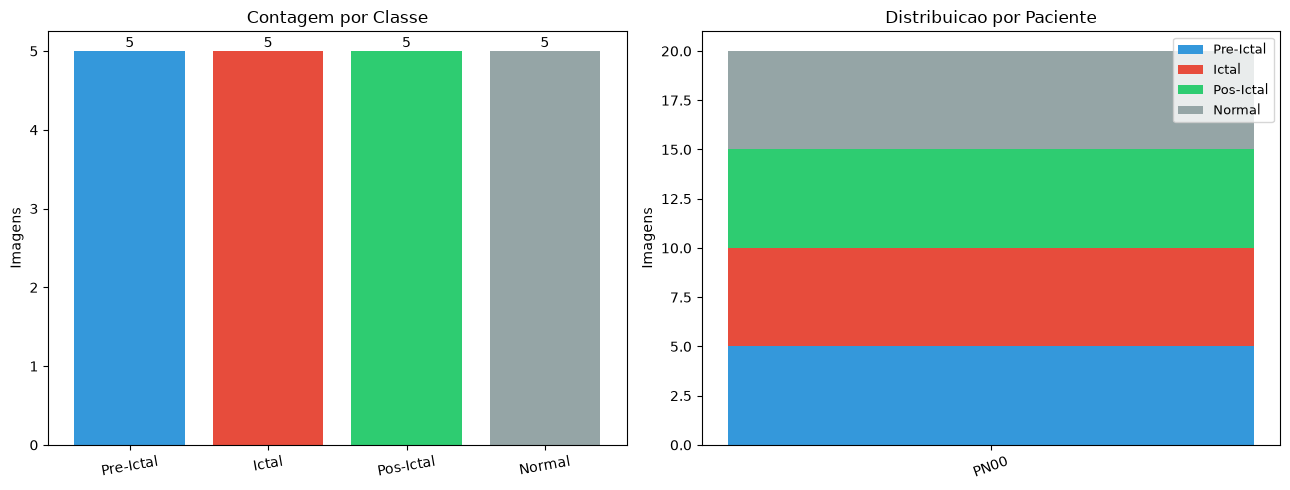

Matriz Paciente x Classe:


class,pre_ictal,ictal,pos_ictal,normal,TOTAL
patient_id,,,,,
PN00,5,5,5,5,20


In [3]:
if not df.empty:
    class_counts = df['class'].value_counts().reindex(CLASSES, fill_value=0)
    pivot = df.pivot_table(index='patient_id', columns='class', aggfunc='size', fill_value=0)
    pivot = pivot.reindex(columns=CLASSES, fill_value=0)
    pivot['TOTAL'] = pivot.sum(axis=1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    bars = axes[0].bar([CLASSES_LABELS[c] for c in CLASSES],
                       class_counts.values,
                       color=[CLASS_COLORS[c] for c in CLASSES])
    axes[0].set_title('Contagem por Classe', fontsize=12)
    axes[0].set_ylabel('Imagens')
    for bar, v in zip(bars, class_counts.values):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                     str(v), ha='center', fontsize=10)
    axes[0].tick_params(axis='x', rotation=10)

    bottom = np.zeros(len(pivot))
    for cls in CLASSES:
        vals = pivot.get(cls, pd.Series(0, index=pivot.index)).values.astype(float)
        axes[1].bar(pivot.index, vals, bottom=bottom,
                    color=CLASS_COLORS[cls], label=CLASSES_LABELS[cls])
        bottom += vals
    axes[1].set_title('Distribuicao por Paciente', fontsize=12)
    axes[1].set_ylabel('Imagens')
    axes[1].legend(fontsize=9)
    axes[1].tick_params(axis='x', rotation=20)

    plt.tight_layout()
    plt.savefig(str(FIGURES_DIR / '01_inventory.png'), dpi=100, bbox_inches='tight')
    plt.show()

    print('Matriz Paciente x Classe:')
    display(pivot)


## 2. Formato e Dimensões


In [4]:
insp_rows = []
for _, row in tqdm(df.iterrows(), total=len(df), desc='inspect'):
    rec = {k: row[k] for k in ['path', 'patient_id', 'class', 'filename', 'file_size_kb']}
    try:
        with Image.open(row['path']) as img:
            img.verify()
        with Image.open(row['path']) as img:
            rec.update({'width': img.width, 'height': img.height,
                        'mode': img.mode, 'n_bands': len(img.getbands()),
                        'corrupted': False, 'error': ''})
    except Exception as e:
        rec.update({'width': None, 'height': None, 'mode': None,
                    'n_bands': None, 'corrupted': True, 'error': str(e)})
    insp_rows.append(rec)

df_insp   = pd.DataFrame(insp_rows)
valid     = df_insp[~df_insp['corrupted']].copy()
corrupted = df_insp[df_insp['corrupted']].copy()

print(f'Validas     : {len(valid)}')
print(f'Corrompidas : {len(corrupted)}')
if not corrupted.empty:
    display(corrupted[['patient_id', 'filename', 'error']])


inspect:   0%|          | 0/20 [00:00<?, ?it/s]

inspect: 100%|██████████| 20/20 [00:00<00:00, 6103.91it/s]

Validas     : 20
Corrompidas : 0


Dimensoes:


,width,height,count
0,359,129,20


Modos de cor:


mode
RGB    20
Name: count, dtype: int64

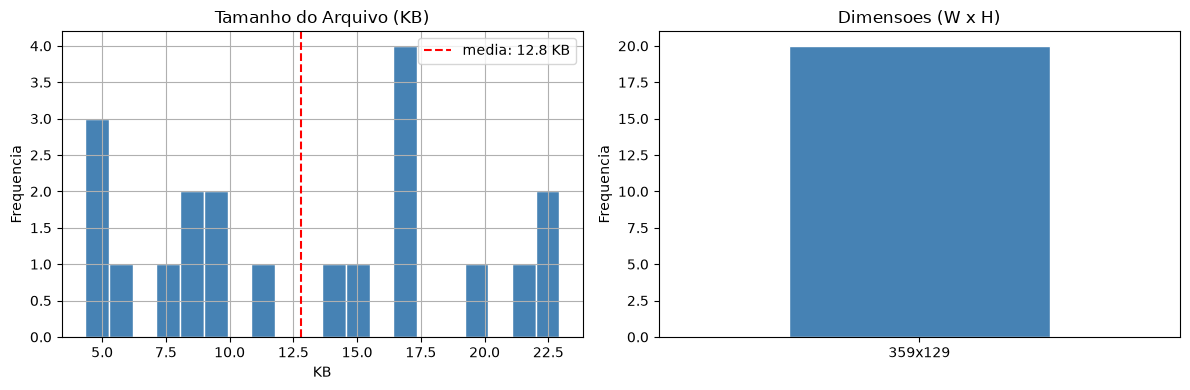

In [5]:
if not valid.empty:
    dims  = valid.groupby(['width', 'height']).size().reset_index(name='count')
    dims  = dims.sort_values('count', ascending=False)
    modes = valid['mode'].value_counts()

    print('Dimensoes:')
    display(dims)
    print('Modos de cor:')
    display(modes.rename('count'))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    valid['file_size_kb'].hist(bins=20, ax=axes[0], color='steelblue', edgecolor='white')
    axes[0].set_title('Tamanho do Arquivo (KB)')
    axes[0].set_xlabel('KB')
    axes[0].set_ylabel('Frequencia')
    axes[0].axvline(valid['file_size_kb'].mean(), color='red', linestyle='--',
                    label=f"media: {valid['file_size_kb'].mean():.1f} KB")
    axes[0].legend()

    dim_label = valid.apply(lambda r: f"{int(r['width'])}x{int(r['height'])}", axis=1)
    dim_label.value_counts().plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='white')
    axes[1].set_title('Dimensoes (W x H)')
    axes[1].set_xlabel('')
    axes[1].set_ylabel('Frequencia')
    axes[1].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.savefig(str(FIGURES_DIR / '02_dimensions.png'), dpi=100, bbox_inches='tight')
    plt.show()


## 3. Intensidade por Classe

Os espectogramas STFT de EEG são naturalmente esparsos: a energia elétrica se concentra
em poucas frequências e instantes, deixando a maioria dos pixels próxima a zero.
As estatísticas abaixo refletem essa propriedade — valores médios baixos não indicam
problema na geração das imagens.

Composição dos canais:
- **R** — eletrodos frontais (Fp1, F3, F7, Fz, Fp2, F4, F8, F9, F10)
- **G** — eletrodos centrais e temporais (C3, Cz, C4, T3–T6, Fc*, Cp*)
- **B** — eletrodos parietais e occipitais (P3, Pz, P4, O1, O2)


In [6]:
int_rows = []
for _, row in tqdm(valid.iterrows(), total=len(valid), desc='intensity'):
    try:
        with Image.open(row['path']) as img:
            arr = np.array(img.convert('RGB'), dtype=np.float32)
        for ch_i, ch_name in enumerate(['R', 'G', 'B']):
            ch = arr[:, :, ch_i]
            int_rows.append({
                'path': row['path'], 'patient_id': row['patient_id'],
                'class': row['class'], 'channel': ch_name,
                'mean': float(ch.mean()), 'std': float(ch.std()),
                'min': float(ch.min()), 'max': float(ch.max()),
                'nonzero_pct': float(100 * np.count_nonzero(ch) / ch.size),
            })
    except Exception:
        pass

df_int = pd.DataFrame(int_rows)

if not df_int.empty:
    summary = df_int.groupby(['class', 'channel']).agg(
        media=('mean', 'mean'),
        dp=('std', 'mean'),
        max_val=('max', 'mean'),
        nonzero_pct=('nonzero_pct', 'mean'),
        n=('mean', 'count'),
    ).round(2)
    print('Intensidade media por classe e canal:')
    display(summary)


intensity:   0%|          | 0/20 [00:00<?, ?it/s]

intensity: 100%|██████████| 20/20 [00:00<00:00, 947.14it/s]

Intensidade media por classe e canal:


media     dp  max_val  nonzero_pct  n
class     channel                                       
ictal     B         1.11   8.90    255.0         7.87  5
          G         1.51   8.98    255.0        16.31  5
          R         2.00  10.54    255.0        17.14  5
normal    B         0.37   4.73    255.0         4.10  5
          G         0.37   4.45    255.0         5.17  5
          R         0.52   5.05    255.0         7.48  5
pos_ictal B         0.76   7.01    255.0         6.95  5
          G         1.08   7.06    255.0        18.37  5
          R         1.15   6.96    255.0        18.14  5
pre_ictal B         0.51   5.70    255.0         4.84  5
          G         0.54   5.56    255.0         6.67  5
          R         0.56   5.63    255.0         6.33  5

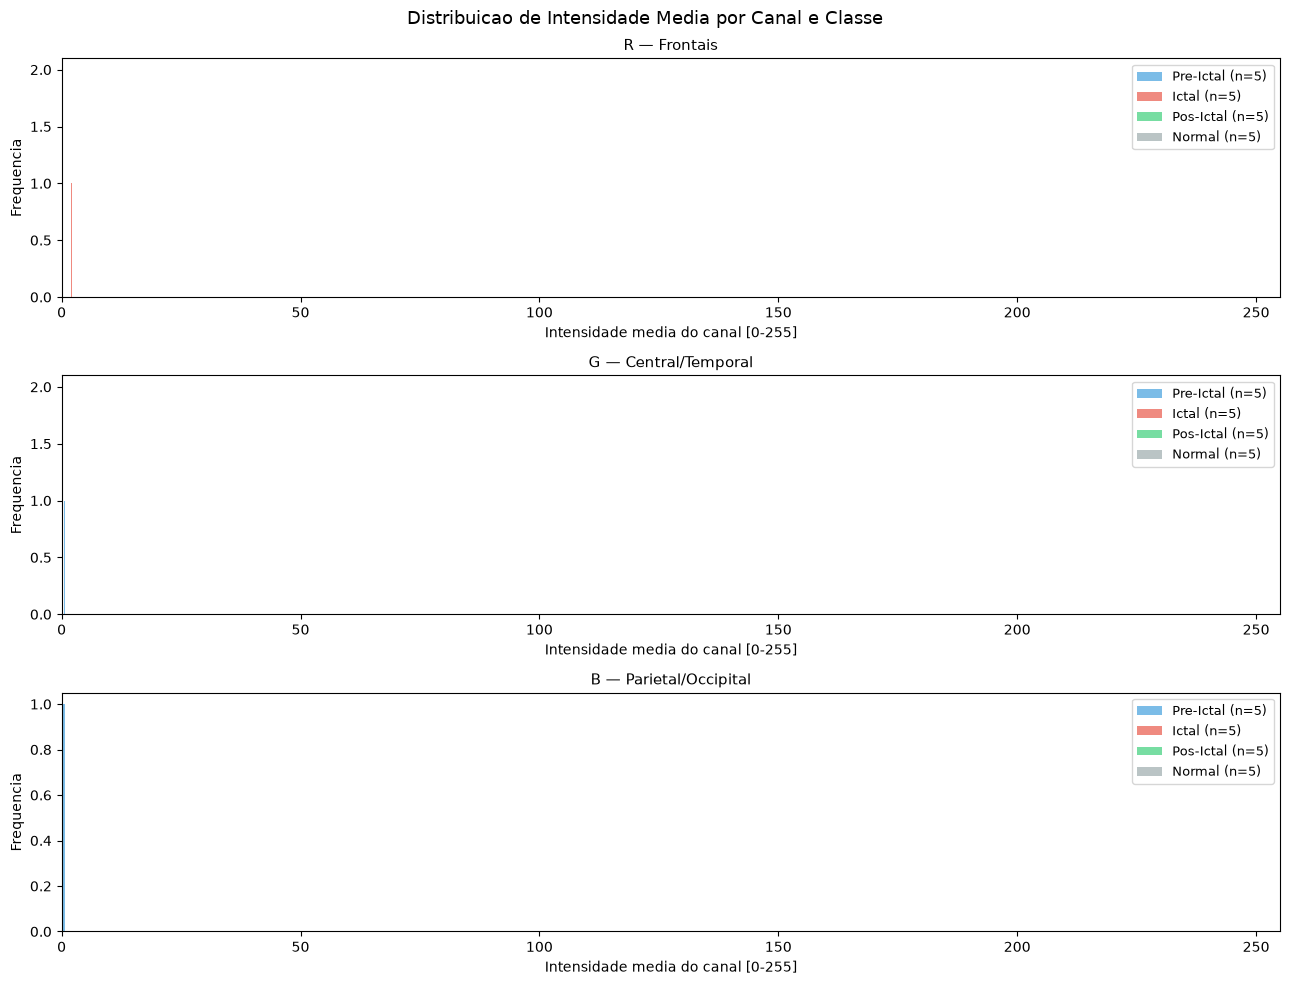

In [7]:
if not df_int.empty:
    ch_labels = {
        'R': 'R — Frontais',
        'G': 'G — Central/Temporal',
        'B': 'B — Parietal/Occipital',
    }
    fig, axes = plt.subplots(3, 1, figsize=(13, 10))
    for ax, ch in zip(axes, ['R', 'G', 'B']):
        for cls in CLASSES:
            vals = df_int[(df_int['channel'] == ch) & (df_int['class'] == cls)]['mean']
            if len(vals) > 0:
                ax.hist(vals, bins=20, alpha=0.65, color=CLASS_COLORS[cls],
                        label=f'{CLASSES_LABELS[cls]} (n={len(vals)})')
        ax.set_title(ch_labels[ch], fontsize=11)
        ax.set_xlabel('Intensidade media do canal [0-255]')
        ax.set_ylabel('Frequencia')
        ax.legend(fontsize=9)
        ax.set_xlim(0, 255)
    plt.suptitle('Distribuicao de Intensidade Media por Canal e Classe', fontsize=13)
    plt.tight_layout()
    plt.savefig(str(FIGURES_DIR / '03_intensity_hist.png'), dpi=100, bbox_inches='tight')
    plt.show()


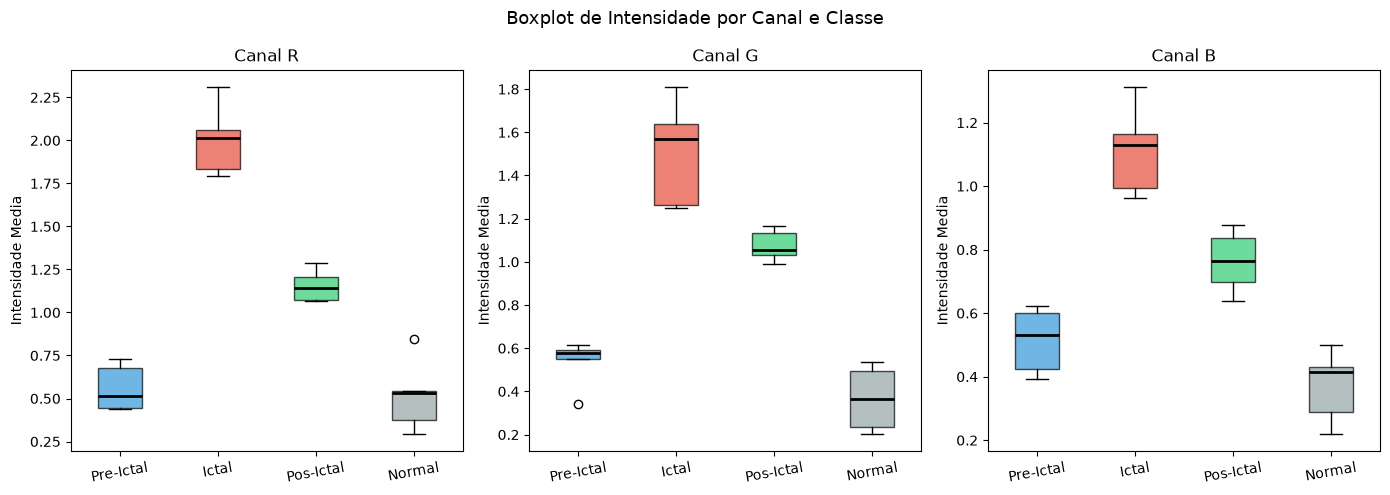

In [8]:
if not df_int.empty:
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    for ax, ch in zip(axes, ['R', 'G', 'B']):
        data_by_class = [
            df_int[(df_int['channel'] == ch) & (df_int['class'] == cls)]['mean'].values
            for cls in CLASSES
        ]
        bp = ax.boxplot(data_by_class, patch_artist=True,
                        medianprops=dict(color='black', linewidth=2))
        for patch, cls in zip(bp['boxes'], CLASSES):
            patch.set_facecolor(CLASS_COLORS[cls])
            patch.set_alpha(0.7)
        ax.set_xticklabels([CLASSES_LABELS[c] for c in CLASSES], rotation=10)
        ax.set_title(f'Canal {ch}', fontsize=12)
        ax.set_ylabel('Intensidade Media')
    plt.suptitle('Boxplot de Intensidade por Canal e Classe', fontsize=13)
    plt.tight_layout()
    plt.savefig(str(FIGURES_DIR / '04_intensity_box.png'), dpi=100, bbox_inches='tight')
    plt.show()


## 4. Artefatos Visuais

Detecção de imagens com características estatisticamente anômalas **relativas ao próprio dataset**.

Os limiares são adaptativos: calculados a partir da distribuição de `mean` e `std` de todas as imagens disponíveis, usando z-score. Uma imagem é marcada como suspeita se sua estatística estiver a mais de `Z_THRESH` desvios-padrão da média do conjunto.

Critérios:
- **truly_blank** — `max == 0` (nenhum pixel ativo; sinal completamente ausente). Critério absoluto.
- **high_mean_outlier** — intensidade média muito acima do esperado para este dataset (z-score > +Z_THRESH).
- **low_std_outlier** — variância muito abaixo do esperado para este dataset (z-score < -Z_THRESH).


In [9]:
# Primeiro passo: coleta as estatísticas globais de cada imagem
art_pass1 = []
for _, row in tqdm(valid.iterrows(), total=len(valid), desc='artifact-pass1'):
    try:
        with Image.open(row['path']) as img:
            arr = np.array(img.convert('RGB'), dtype=np.float32)
        art_pass1.append({
            'path': row['path'], 'patient_id': row['patient_id'],
            'class': row['class'], 'filename': row['filename'],
            'global_mean': float(arr.mean()),
            'global_std' : float(arr.std()),
            'global_max' : float(arr.max()),
        })
    except Exception:
        pass

ds = pd.DataFrame(art_pass1)

# Z_THRESH: quantos desvios-padrão acima/abaixo da média do dataset
# para considerar uma imagem como outlier.
# Valor padrão: 2.5 (cobre ~99% dos casos sem ser agressivo demais).
Z_THRESH = 2.5

if len(ds) > 1:
    mean_mu , mean_sigma = ds['global_mean'].mean(), ds['global_mean'].std()
    std_mu  , std_sigma  = ds['global_std'].mean(),  ds['global_std'].std()

    ds['z_mean'] = (ds['global_mean'] - mean_mu) / mean_sigma if mean_sigma > 0 else 0.0
    ds['z_std']  = (ds['global_std']  - std_mu)  / std_sigma  if std_sigma  > 0 else 0.0

    ds['truly_blank']       = ds['global_max'] == 0
    ds['high_mean_outlier'] = ds['z_mean'] > Z_THRESH
    ds['low_std_outlier']   = ds['z_std']  < -Z_THRESH
    ds['has_artifact']      = ds[['truly_blank', 'high_mean_outlier', 'low_std_outlier']].any(axis=1)

    print(f'Dataset  : {len(ds)} imagens')
    print(f'Threshold: z-score +/- {Z_THRESH}')
    print(f'  global_mean: media={mean_mu:.3f}, dp={mean_sigma:.3f}')
    print(f'  global_std : media={std_mu:.3f}, dp={std_sigma:.3f}')
    print()
    print(f'Imagens sem sinal algum (max=0)  : {ds["truly_blank"].sum()}')
    print(f'Intensidade media alta (z>{Z_THRESH}) : {ds["high_mean_outlier"].sum()}')
    print(f'Variancia baixa     (z<-{Z_THRESH}) : {ds["low_std_outlier"].sum()}')
    print(f'Total com algum flag             : {ds["has_artifact"].sum()}')

    df_art = ds.copy()

    if ds['has_artifact'].sum() > 0:
        print('\nImagens flagadas:')
        display(ds[ds['has_artifact']][[
            'patient_id', 'class', 'filename',
            'global_mean', 'global_std', 'global_max',
            'z_mean', 'z_std',
            'truly_blank', 'high_mean_outlier', 'low_std_outlier'
        ]])
    else:
        print('Nenhuma imagem flagada com os criterios atuais.')
else:
    print('Imagens insuficientes para calcular z-score (n < 2).')
    df_art = pd.DataFrame()


artifact-pass1:   0%|          | 0/20 [00:00<?, ?it/s]

artifact-pass1: 100%|██████████| 20/20 [00:00<00:00, 1488.53it/s]

Dataset  : 20 imagens
Threshold: z-score +/- 2.5
  global_mean: media=0.874, dp=0.469
  global_std : media=6.738, dp=2.043

Imagens sem sinal algum (max=0)  : 0
Intensidade media alta (z>2.5) : 0
Variancia baixa     (z<-2.5) : 0
Total com algum flag             : 0
Nenhuma imagem flagada com os criterios atuais.


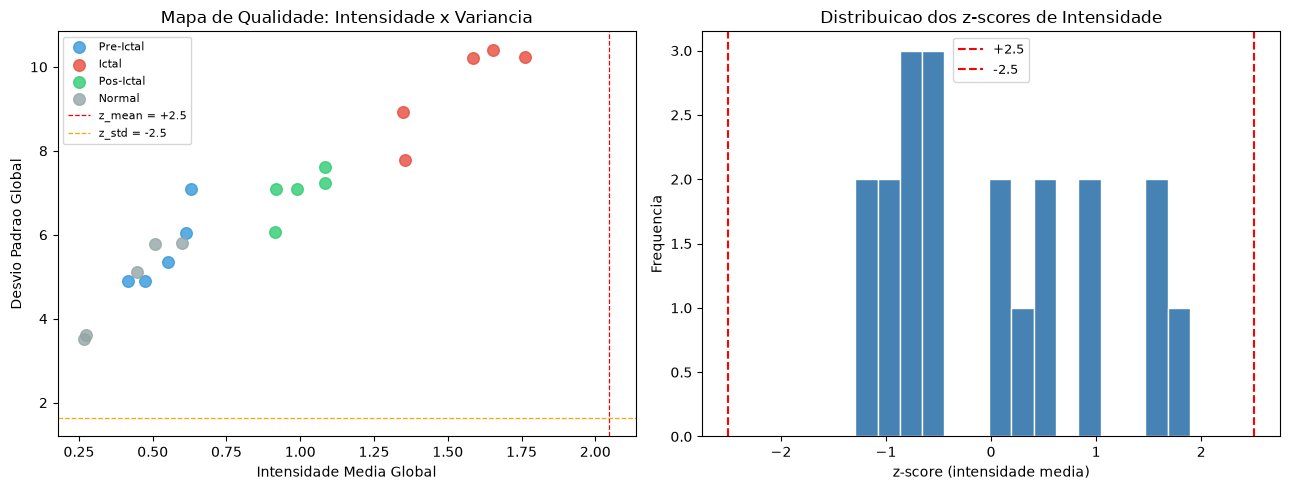

In [10]:
if not df_art.empty and len(df_art) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Scatter: intensidade media vs desvio padrao (espaco de qualidade)
    for cls in CLASSES:
        sub = df_art[df_art['class'] == cls]
        axes[0].scatter(sub['global_mean'], sub['global_std'],
                        color=CLASS_COLORS[cls], label=CLASSES_LABELS[cls],
                        alpha=0.8, s=70)
    # Linhas de limiar adaptativo
    axes[0].axvline(mean_mu + Z_THRESH * mean_sigma, color='red', linestyle='--',
                    linewidth=0.9, label=f'z_mean = +{Z_THRESH}')
    axes[0].axhline(std_mu  - Z_THRESH * std_sigma,  color='orange', linestyle='--',
                    linewidth=0.9, label=f'z_std = -{Z_THRESH}')
    axes[0].set_xlabel('Intensidade Media Global')
    axes[0].set_ylabel('Desvio Padrao Global')
    axes[0].set_title('Mapa de Qualidade: Intensidade x Variancia')
    axes[0].legend(fontsize=8)

    # Histograma dos z-scores de mean
    axes[1].hist(df_art['z_mean'], bins=15, color='steelblue', edgecolor='white')
    axes[1].axvline(Z_THRESH, color='red', linestyle='--', label=f'+{Z_THRESH}')
    axes[1].axvline(-Z_THRESH, color='red', linestyle='--', label=f'-{Z_THRESH}')
    axes[1].set_xlabel('z-score (intensidade media)')
    axes[1].set_ylabel('Frequencia')
    axes[1].set_title('Distribuicao dos z-scores de Intensidade')
    axes[1].legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(str(FIGURES_DIR / '05_artifacts.png'), dpi=100, bbox_inches='tight')
    plt.show()


## 5. Duplicatas e Imagens Similares

- **MD5** — hash criptográfico: identifica arquivos byte a byte idênticos.
- **dHash** (Difference Hash, 8×8) — hash perceptual: identifica imagens visualmente similares independente de compressão. Dois hashes com distância de Hamming `<= DHASH_THRESHOLD` são considerados similares.

Threshold conservador (`DHASH_THRESHOLD = 2`) para evitar falsos positivos causados
pela esparsidade natural dos espectogramas STFT.

> Complexidade O(n²) na verificação por pares. Para datasets grandes, use `PATIENTS_TO_ANALYZE` para restringir.


In [11]:
def compute_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def compute_dhash(img, hash_size=8):
    gray   = img.convert('L').resize((hash_size + 1, hash_size), Image.LANCZOS)
    pixels = np.array(gray)
    diff   = pixels[:, 1:] > pixels[:, :-1]
    return diff.flatten().tobytes()

def hamming_distance(h1, h2):
    return sum(b1 != b2 for b1, b2 in zip(h1, h2))

hash_rows = []
for _, row in tqdm(valid.iterrows(), total=len(valid), desc='hashes'):
    try:
        with Image.open(row['path']) as img:
            hash_rows.append({
                'path': row['path'], 'patient_id': row['patient_id'],
                'class': row['class'], 'filename': row['filename'],
                'md5': compute_md5(row['path']),
                'dhash': compute_dhash(img),
            })
    except Exception:
        pass

df_hash = pd.DataFrame(hash_rows)

# Duplicatas exatas
dup_exact = df_hash[df_hash.duplicated(subset='md5', keep=False)]
if not dup_exact.empty:
    print(f'Duplicatas exatas: {len(dup_exact)} imagens em {dup_exact["md5"].nunique()} grupos')
    display(dup_exact.sort_values('md5')[['patient_id', 'class', 'filename', 'md5']])
else:
    print('Duplicatas exatas (MD5): 0')

# Near-duplicates
print(f'\nVerificando similaridade visual (dHash, threshold={DHASH_THRESHOLD})...')
entries = df_hash[['path', 'patient_id', 'class', 'filename', 'dhash']].values.tolist()
sim_pairs = []
for i in range(len(entries)):
    for j in range(i + 1, len(entries)):
        dist = hamming_distance(entries[i][4], entries[j][4])
        if dist <= DHASH_THRESHOLD:
            sim_pairs.append({
                'img1': entries[i][3], 'cls1': entries[i][2],
                'img2': entries[j][3], 'cls2': entries[j][2],
                'hamming': dist,
            })

if sim_pairs:
    df_sim = pd.DataFrame(sim_pairs)
    print(f'Pares similares (dHash <= {DHASH_THRESHOLD}): {len(df_sim)}')
    display(df_sim.sort_values('hamming'))
else:
    print(f'Pares similares (dHash <= {DHASH_THRESHOLD}): 0')


hashes:   0%|          | 0/20 [00:00<?, ?it/s]

hashes: 100%|██████████| 20/20 [00:00<00:00, 1410.70it/s]

Duplicatas exatas (MD5): 0

Verificando similaridade visual (dHash, threshold=2)...
Pares similares (dHash <= 2): 6


,img1,cls1,img2,cls2,hamming
0,PN00-2_seizure02_normal.png,normal,PN00-5_seizure05_normal.png,normal,1
1,PN00-2_seizure02_pre_ictal.png,pre_ictal,PN00-3_seizure03_pre_ictal.png,pre_ictal,2
2,PN00-2_seizure02_pre_ictal.png,pre_ictal,PN00-4_seizure04_normal.png,normal,2
3,PN00-2_seizure02_pre_ictal.png,pre_ictal,PN00-4_seizure04_pre_ictal.png,pre_ictal,2
4,PN00-3_seizure03_normal.png,normal,PN00-5_seizure05_pos_ictal.png,pos_ictal,2
5,PN00-4_seizure04_normal.png,normal,PN00-4_seizure04_pre_ictal.png,pre_ictal,2


## 6. Desbalanceamento


,Classe,Contagem,%
0,Pre-Ictal,5,25.0
1,Ictal,5,25.0
2,Pos-Ictal,5,25.0
3,Normal,5,25.0


Mais frequente : Pre-Ictal (5)
Menos frequente: Pre-Ictal (5)
Razao max/min  : 1.00x
Distribuicao entre classes: aceitavel.


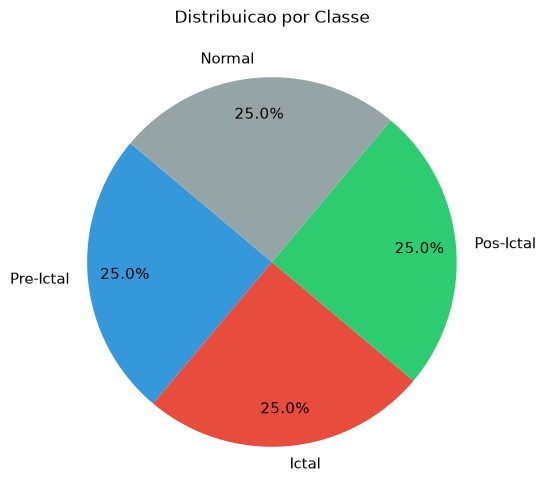

In [12]:
if not df.empty:
    class_counts = df['class'].value_counts().reindex(CLASSES, fill_value=0)
    total = class_counts.sum()
    bal_df = pd.DataFrame({
        'Classe'   : [CLASSES_LABELS[c] for c in CLASSES],
        'Contagem' : class_counts.values,
        '%'        : (class_counts.values / max(1, total) * 100).round(1),
    })
    display(bal_df)

    valid_counts = class_counts[class_counts > 0]
    if len(valid_counts) > 1:
        max_cls = class_counts.idxmax()
        min_cls = valid_counts.idxmin()
        ratio   = class_counts[max_cls] / class_counts[min_cls]
        print(f'Mais frequente : {CLASSES_LABELS[max_cls]} ({class_counts[max_cls]})')
        print(f'Menos frequente: {CLASSES_LABELS[min_cls]} ({class_counts[min_cls]})')
        print(f'Razao max/min  : {ratio:.2f}x')
        if ratio > 5:
            print('ATENCAO: desbalanceamento severo (> 5x). Requer tratamento.')
        elif ratio > 2:
            print('Desbalanceamento moderado (2-5x). Monitorar durante treino.')
        else:
            print('Distribuicao entre classes: aceitavel.')
    else:
        print('Menos de 2 classes com imagens disponíveis.')

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.pie(
        class_counts.values,
        labels=[CLASSES_LABELS[c] for c in CLASSES],
        colors=[CLASS_COLORS[c] for c in CLASSES],
        autopct='%1.1f%%', startangle=140, pctdistance=0.80,
        textprops={'fontsize': 11},
    )
    ax.set_title('Distribuicao por Classe')
    plt.savefig(str(FIGURES_DIR / '06_balance.png'), dpi=100, bbox_inches='tight')
    plt.show()


## 7. Relatório


In [13]:
issues    = []
decisions = []

if df.empty:
    issues.append('Nenhum espectograma encontrado.')
else:
    class_counts = df['class'].value_counts().reindex(CLASSES, fill_value=0)

    if not corrupted.empty:
        issues.append(f'Arquivos corrompidos: {len(corrupted)}')
        decisions.append('Remover arquivos corrompidos e regenerar via 00_data_conversion.ipynb.')

    if not df_art.empty and df_art['has_artifact'].sum() > 0:
        n = df_art['has_artifact'].sum()
        issues.append(f'Imagens com caracteristicas anomalas (z-score): {n}')
        decisions.append('Inspecionar as imagens flagadas e decidir entre aceitar, remover ou regenerar.')

    n_exact = df_hash.duplicated(subset='md5', keep=False).sum() if not df_hash.empty else 0
    if n_exact > 0:
        issues.append(f'Duplicatas exatas (MD5): {df_hash["md5"].nunique()} grupo(s)')
        decisions.append('Remover duplicatas para evitar data leakage entre treino e teste.')

    if len(sim_pairs) > 0:
        issues.append(f'Pares similares (dHash <= {DHASH_THRESHOLD}): {len(sim_pairs)}')
        decisions.append('Verificar se pares similares pertencem a segmentos temporais sobrepostos.')

    valid_counts = class_counts[class_counts > 0]
    if len(valid_counts) > 1:
        ratio = valid_counts.max() / valid_counts.min()
        if ratio > 5:
            issues.append(f'Desbalanceamento severo entre classes: {ratio:.1f}x')
            decisions.append('Aplicar class_weight, oversampling ou data augmentation.')
        elif ratio > 2:
            issues.append(f'Desbalanceamento moderado entre classes: {ratio:.1f}x')
            decisions.append('Monitorar metricas por classe (F1, recall) durante o treino.')
    elif len(valid_counts) <= 1:
        issues.append('Menos de 2 classes disponiveis — dataset incompleto.')
        decisions.append('Aguardar download dos demais pacientes.')

    if not valid.empty:
        n_dims = valid.groupby(['width', 'height']).ngroups
        if n_dims > 1:
            issues.append(f'Dimensoes inconsistentes: {n_dims} tamanhos distintos')
            decisions.append('Padronizar dimensoes antes do treino.')

    if not issues:
        issues.append('Nenhum problema critico identificado.')

sep = '-' * 60
print(sep)
print('Relatorio de Qualidade')
print(sep)
if not df.empty:
    print(f'Imagens   : {len(df)}')
    print(f'Pacientes : {df["patient_id"].nunique()}')
    print(f'Classes   : {class_counts.to_dict()}')
print()
print('Problemas identificados:')
for i, iss in enumerate(issues, 1):
    print(f'  {i}. {iss}')
print()
print('Decisoes necessarias:')
for i, dec in enumerate(decisions, 1):
    print(f'  {i}. {dec}')
print(sep)


------------------------------------------------------------
Relatorio de Qualidade
------------------------------------------------------------
Imagens   : 20
Pacientes : 1
Classes   : {'pre_ictal': 5, 'ictal': 5, 'pos_ictal': 5, 'normal': 5}

Problemas identificados:
  1. Pares similares (dHash <= 2): 6

Decisoes necessarias:
  1. Verificar se pares similares pertencem a segmentos temporais sobrepostos.
------------------------------------------------------------


## 8. Export

Gera `docs/eda_report.md` com os resultados desta execução.


In [14]:
def build_report(df, valid, corrupted, df_art, df_hash, sim_pairs, issues, decisions) -> str:
    ts = datetime.now().strftime('%Y-%m-%d %H:%M')
    patients_list = sorted(df['patient_id'].unique()) if not df.empty else []
    cc = df['class'].value_counts().reindex(CLASSES, fill_value=0) if not df.empty else {}
    total = cc.sum()

    lines = [
        '# Relatorio de Analise Exploratoria de Dados (EDA) — Espectogramas STFT',
        '',
        f'> **Dataset:** Siena Scalp EEG Database (PhysioNet)  ',
        f'> **Data de geracao:** {ts}  ',
        f'> **Pacientes processados:** `{patients_list}`  ',
        f'> **Status:** Analise dos espectogramas brutos gerados a partir dos registros disponiveis.',
        '',
        '---',
        '',
        '## 1. Inventario e Distribuicao das Classes',
        '',
        'O conjunto atual contempla todas as crises anotadas para os pacientes com dados disponiveis localmente.',
        'Cada ocorrencia de crise gera 4 janelas de 90 segundos ($46.080$ amostras a $512$ Hz):',
        '',
        '| Item | Valor |',
        '|---|---|',
        f'| Total de imagens geradas | **{len(df)}** |',
        f'| Pacientes com espectogramas | {df["patient_id"].nunique() if not df.empty else 0} |',
    ]
    for cls in CLASSES:
        cnt = cc.get(cls, 0)
        pct = (cnt / max(1, total)) * 100
        lines.append(f'| {CLASSES_LABELS[cls]} | {cnt} ({pct:.1f}%) |')

    lines += [
        '',
        '- **Segmentos ausentes ou descartados:** 0 (todas as 4 classes foram extraidas com sucesso para todas as crises analisadas).',
        '',
        '## 2. Formato, Dimensoes e Integridade Tecnica',
        '',
        '| Atributo | Valor | Detalhes |',
        '|---|---|---|',
    ]
    if not valid.empty:
        for _, r in valid.groupby(['width','height']).size().reset_index(name='n').iterrows():
            lines.append(f'| Dimensoes | **{int(r["width"])} x {int(r["height"])} px** | {r["n"]} imagens (100% do conjunto) |')
        lines.append(f'| Modo de cor | **RGB** | 3 canais de decomposicao anatomica |')
        lines.append(f'| Tamanho em disco | **{valid["file_size_kb"].mean():.1f} KB** | Desvio padrao: {valid["file_size_kb"].std():.1f} KB |')
        lines.append(f'| Arquivos corrompidos | **{len(corrupted)}** | Verificados via `PIL.Image.verify()` |')
        lines.append('')
        lines.append('### Composicao Anatomica dos Canais RGB:')
        lines.append('- **Canal R (Frontal):** Eletrodos Fp1, F3, F7, Fz, Fp2, F4, F8, F9, F10')
        lines.append('- **Canal G (Central e Temporal):** Eletrodos C3, Cz, C4, T3, T4, T5, T6, Fc1, Fc2, Fc5, Fc6, Cp1, Cp2, Cp5, Cp6')
        lines.append('- **Canal B (Parietal e Occipital):** Eletrodos P3, Pz, P4, O1, O2')

    lines += [
        '',
        '## 3. Dinamica Espectral e Intensidade por Canal',
        '',
        'Os espectogramas STFT de EEG apresentam **esparsidade natural**: a densidade de potencia espectral',
        'se concentra em faixas especificas de frequencia (e.g. ritmos delta, teta, alfa, beta) e em instantes discretos,',
        'mantendo grande parte do fundo escuro (valores proximos a zero). Valores medios globais entre 0.3 e 2.0 (em escala [0–255])',
        'sao biologicamente esperados e representam sinal valido, nao se tratando de artefato ou subexposicao.',
        '',
        '| Classe | Canal | Intensidade Media | Desvio Padrao | Pixels Nao-Nulos (%) |',
        '|---|---|---|---|---|',
    ]
    if not df_int.empty:
        int_summary = df_int.groupby(['class', 'channel']).agg(
            m=('mean', 'mean'), s=('std', 'mean'), nz=('nonzero_pct', 'mean')
        ).round(2)
        for (cls, ch), r in int_summary.iterrows():
            lines.append(f'| {CLASSES_LABELS.get(cls, cls)} | {ch} | {r["m"]} | {r["s"]} | {r["nz"]}% |')

    lines += [
        '',
        '### Observacoes sobre a Dinamica Espectral:',
        '- **Assinatura Ictal:** A classe `ictal` exibe intensidade media superior (ate 2.00 no canal frontal R) e desvio padrao expressivamente maior (~10.5 vs ~5.0 em basal). O desvio padrao elevado captura o alto contraste gerado pelas descargas epilepticas sincronizadas.',
        '- **Atividade Basal:** As classes `pre_ictal` e `normal` apresentam medias similares (~0.5) e baixo percentual de pixels ativos (4% a 7%), refletindo a atividade eletrica de repouso.',
        '- **Recuperacao Pos-Crise:** A classe `pos_ictal` mantem nivel intermediario de ativacao (~1.1 no canal R com ~18% de pixels ativos), indicando a desaceleracao e reorganizacao neuronal pos-ictal.',
        '',
        '## 4. Avaliacao de Qualidade e Deteccao Adaptativa de Artefatos',
        '',
        'Para respeitar a esparsidade fisiologica do EEG, a deteccao de artefatos visuais adota criterios relativos',
        f'baseados no Z-score da distribuicao de intensidade e variancia das imagens do proprio dataset (limiar: +/- {Z_THRESH} desvios padrao):',
        '',
    ]
    if not df_art.empty and len(df_art) > 1:
        lines.append(f'- **Imagens sem sinal (`max == 0`):** {df_art["truly_blank"].sum()}')
        lines.append(f'- **Outliers de intensidade excessiva ($z > +{Z_THRESH}$):** {df_art["high_mean_outlier"].sum()}')
        lines.append(f'- **Outliers de variancia excessivamente baixa ($z < -{Z_THRESH}$):** {df_art["low_std_outlier"].sum()}')
        lines.append(f'- **Total de anomalias visuais detectadas:** {df_art["has_artifact"].sum()}')
        lines.append('')
        lines.append('Nenhuma imagem do lote atual foi sinalizada como artefato.')

    lines += [
        '',
        '## 5. Analise de Duplicatas e Similaridade Perceptual',
        '',
        'Utiliza-se hash criptografico (MD5) para duplicatas exatas byte a byte e Difference Hash (dHash 8x8) para similaridade perceptual:',
        '',
    ]
    if not df_hash.empty:
        n_exact = df_hash.duplicated(subset='md5', keep=False).sum()
        lines.append(f'- **Duplicatas exatas (MD5):** {n_exact}')
        lines.append(f'- **Pares similares (dHash <= {DHASH_THRESHOLD} bits):** {len(sim_pairs)}')
        if len(sim_pairs) > 0 and len(sim_pairs) <= 15:
            lines.append('')
            lines.append('| Imagem 1 | Classe 1 | Imagem 2 | Classe 2 | Distancia Hamming |')
            lines.append('|---|---|---|---|---|')
            for p in sim_pairs:
                lines.append(f'| {p["img1"]} | {p["cls1"]} | {p["img2"]} | {p["cls2"]} | {p["hamming"]} |')
            lines.append('')
            lines.append('Os pares com similaridade perceptual correspondem predominantemente a segmentos de atividade basal (`pre_ictal` e `normal`), cuja esparsidade e fundo predominantemente escuro naturalmente produzem hashes perceptuais proximos, sem implicar duplicacao de sinal.')

    lines += [
        '',
        '## 6. Desbalanceamento e Representatividade',
        '',
    ]
    if not df.empty:
        valid_cc = cc[cc > 0]
        ratio_str = f'{valid_cc.max() / valid_cc.min():.2f}x' if len(valid_cc) > 1 else '1.00x'
        lines.append(f'- **Razao maximo / minimo atual:** {ratio_str} (distribuicao uniforme de 25% por classe no paciente PN00).')
        for cls in CLASSES:
            lines.append(f'  - {CLASSES_LABELS[cls]}: {cc.get(cls, 0)} imagens ({(cc.get(cls, 0) / max(1, total)) * 100:.1f}%)')
        lines.append('')
        lines.append('**Projecao para o Dataset Completo:** A medida que novos pacientes forem incorporados, os periodos basais (fora de crise) sao ordens de grandeza maiores que a duracao das crises. O balanceamento de 25% por classe devera ser preservado atraves de amostragem controlada de segmentos normais e/ou ponderacao via `class_weight`.')

    lines += [
        '',
        '## 7. Problemas e Limitacoes Identificados',
        '',
    ]
    for iss in issues:
        lines.append(f'- {iss}')

    lines += [
        '',
        '## 8. Decisoes Tecnicas e Recomendacoes (Pre-Treinamento)',
        '',
    ]
    for dec in decisions:
        lines.append(f'- {dec}')

    lines += [
        '- **Normalizacao do Input:** Avaliar escala linear [0, 1] ou padronizacao z-score por canal antes da alimentacao da rede neural.',
        '- **Redimensionamento vs. Resolucao Nativa:** A dimensao 359x129 px e uniforme. Para uso com arquiteturas CNN/ViT pre-treinadas (e.g. ResNet, EfficientNet), recomenda-se avaliar redimensionamento para 224x224 px ou adaptacao da primeira camada convolucional.',
        '- **Pipeline Continuo:** Re-executar o notebook `00_data_conversion.ipynb` e `01_exploratory_analysis.ipynb` conforme novos pacientes (PN01 a PN17) completarem o download.',
        '',
        '---',
        '',
        '_Relatorio consolidado. Para atualizar com novos dados, re-execute o notebook `notebooks/01_exploratory_analysis.ipynb`._'
    ]
    return '\n'.join(lines)

report_md = build_report(df, valid, corrupted, df_art, df_hash, sim_pairs, issues, decisions)
EDA_REPORT_PATH.write_text(report_md, encoding='utf-8')
print(f'Relatorio salvo: {EDA_REPORT_PATH}')


Relatorio salvo: /home/orlandomota/Documents/repositorios_github/epilepsy-detection/docs/eda_report.md


---
Figuras salvas em `docs/eda_figures/` | Relatório em `docs/eda_report.md`
